# Part 1: Data Exploration, Preprocessing and Baseline

## Imports and Settings

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import train_test_split

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (16, 6)
plt.rcParams["font.size"] = 12

pd.set_option('display.max_columns', None)

## Data Exploration and Preprocessing

Number of observations, columns and a few rows of our data.

In [2]:
TRAIN_PATH = os.path.join("data", "train.csv")
TEST_PATH = os.path.join("data", "test.csv")

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Train dataset: ({train_df.shape[0]} observations, {train_df.shape[1]} cols)")
print(f"Test dataset: ({test_df.shape[0]} observations, {test_df.shape[1]} cols)")

train_df.head()

Train dataset: (7352 observations, 563 cols)
Test dataset: (2947 observations, 563 cols)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,tBodyAcc-max()-Y,tBodyAcc-max()-Z,tBodyAcc-min()-X,tBodyAcc-min()-Y,tBodyAcc-min()-Z,tBodyAcc-sma(),tBodyAcc-energy()-X,tBodyAcc-energy()-Y,tBodyAcc-energy()-Z,tBodyAcc-iqr()-X,tBodyAcc-iqr()-Y,tBodyAcc-iqr()-Z,tBodyAcc-entropy()-X,tBodyAcc-entropy()-Y,tBodyAcc-entropy()-Z,"tBodyAcc-arCoeff()-X,1","tBodyAcc-arCoeff()-X,2","tBodyAcc-arCoeff()-X,3","tBodyAcc-arCoeff()-X,4","tBodyAcc-arCoeff()-Y,1","tBodyAcc-arCoeff()-Y,2","tBodyAcc-arCoeff()-Y,3","tBodyAcc-arCoeff()-Y,4","tBodyAcc-arCoeff()-Z,1","tBodyAcc-arCoeff()-Z,2","tBodyAcc-arCoeff()-Z,3","tBodyAcc-arCoeff()-Z,4","tBodyAcc-correlation()-X,Y","tBodyAcc-correlation()-X,Z","tBodyAcc-correlation()-Y,Z",tGravityAcc-mean()-X,tGravityAcc-mean()-Y,tGravityAcc-mean()-Z,tGravityAcc-std()-X,tGravityAcc-std()-Y,tGravityAcc-std()-Z,tGravityAcc-mad()-X,tGravityAcc-mad()-Y,tGravityAcc-mad()-Z,tGravityAcc-max()-X,tGravityAcc-max()-Y,tGravityAcc-max()-Z,tGravityAcc-min()-X,tGravityAcc-min()-Y,tGravityAcc-min()-Z,tGravityAcc-sma(),tGravityAcc-energy()-X,tGravityAcc-energy()-Y,tGravityAcc-energy()-Z,tGravityAcc-iqr()-X,tGravityAcc-iqr()-Y,tGravityAcc-iqr()-Z,tGravityAcc-entropy()-X,tGravityAcc-entropy()-Y,tGravityAcc-entropy()-Z,"tGravityAcc-arCoeff()-X,1","tGravityAcc-arCoeff()-X,2","tGravityAcc-arCoeff()-X,3","tGravityAcc-arCoeff()-X,4","tGravityAcc-arCoeff()-Y,1","tGravityAcc-arCoeff()-Y,2","tGravityAcc-arCoeff()-Y,3","tGravityAcc-arCoeff()-Y,4","tGravityAcc-arCoeff()-Z,1","tGravityAcc-arCoeff()-Z,2","tGravityAcc-arCoeff()-Z,3","tGravityAcc-arCoeff()-Z,4","tGravityAcc-correlation()-X,Y","tGravityAcc-correlation()-X,Z","tGravityAcc-correlation()-Y,Z",tBodyAccJerk-mean()-X,tBodyAccJerk-mean()-Y,tBodyAccJerk-mean()-Z,tBodyAccJerk-std()-X,tBodyAccJerk-std()-Y,tBodyAccJerk-std()-Z,tBodyAccJerk-mad()-X,tBodyAccJerk-mad()-Y,tBodyAccJerk-mad()-Z,tBodyAccJerk-max()-X,tBodyAccJerk-max()-Y,tBodyAccJerk-max()-Z,tBodyAccJerk-min()-X,tBodyAccJerk-min()-Y,tBodyAccJerk-min()-Z,tBodyAccJerk-sma(),tBodyAccJerk-energy()-X,tBodyAccJerk-energy()-Y,tBodyAccJerk-energy()-Z,tBodyAccJerk-iqr()-X,tBodyAccJerk-iqr()-Y,tBodyAccJerk-iqr()-Z,tBodyAccJerk-entropy()-X,tBodyAccJerk-entropy()-Y,tBodyAccJerk-entropy()-Z,"tBodyAccJerk-arCoeff()-X,1","tBodyAccJerk-arCoeff()-X,2","tBodyAccJerk-arCoeff()-X,3","tBodyAccJerk-arCoeff()-X,4","tBodyAccJerk-arCoeff()-Y,1","tBodyAccJerk-arCoeff()-Y,2","tBodyAccJerk-arCoeff()-Y,3","tBodyAccJerk-arCoeff()-Y,4","tBodyAccJerk-arCoeff()-Z,1","tBodyAccJerk-arCoeff()-Z,2","tBodyAccJerk-arCoeff()-Z,3","tBodyAccJerk-arCoeff()-Z,4","tBodyAccJerk-correlation()-X,Y","tBodyAccJerk-correlation()-X,Z","tBodyAccJerk-correlation()-Y,Z",tBodyGyro-mean()-X,tBodyGyro-mean()-Y,tBodyGyro-mean()-Z,tBodyGyro-std()-X,tBodyGyro-std()-Y,tBodyGyro-std()-Z,tBodyGyro-mad()-X,tBodyGyro-mad()-Y,tBodyGyro-mad()-Z,tBodyGyro-max()-X,tBodyGyro-max()-Y,tBodyGyro-max()-Z,tBodyGyro-min()-X,tBodyGyro-min()-Y,tBodyGyro-min()-Z,tBodyGyro-sma(),tBodyGyro-energy()-X,tBodyGyro-energy()-Y,tBodyGyro-energy()-Z,tBodyGyro-iqr()-X,tBodyGyro-iqr()-Y,tBodyGyro-iqr()-Z,tBodyGyro-entropy()-X,tBodyGyro-entropy()-Y,tBodyGyro-entropy()-Z,"tBodyGyro-arCoeff()-X,1","tBodyGyro-arCoeff()-X,2","tBodyGyro-arCoeff()-X,3","tBodyGyro-arCoeff()-X,4","tBodyGyro-arCoeff()-Y,1","tBodyGyro-arCoeff()-Y,2","tBodyGyro-arCoeff()-Y,3","tBodyGyro-arCoeff()-Y,4","tBodyGyro-arCoeff()-Z,1","tBodyGyro-arCoeff()-Z,2","tBodyGyro-arCoeff()-Z,3","tBodyGyro-arCoeff()-Z,4","tBodyGyro-correlation()-X,Y","tBodyGyro-correlation()-X,Z","tBodyGyro-correlation()-Y,Z",tBodyGyroJerk-mean()-X,tBodyGyroJerk-mean()-Y,tBodyGyroJerk-mean()-Z,tBodyGyroJerk-std()-X,tBodyGyroJerk-std()-Y,tBodyGyroJerk-std()-Z,tBodyGyroJerk-mad()-X,tBodyGyroJerk-mad()-Y,tBodyGyroJerk-mad()-Z,tBodyGyroJerk-max()-X,tBodyGyroJerk-max()-Y,tBodyGyroJerk-max()-Z,tBodyGyroJerk-min()-X,tBodyGyroJerk-min()-Y,tBodyGyroJerk-min()-Z,tBodyGyroJ

Identify feature columns, subject column and target column.

In [3]:
target_col = "Activity"
subject_col = "subject"
feature_cols = [c for c in train_df.columns if c not in (target_col, subject_col)]

train_subjects = sorted(int(x) for x in train_df[subject_col].unique())
test_subjects = sorted(int(x) for x in test_df[subject_col].unique())

print(f"{len(feature_cols)} features")
print(f"Train subjects ({len(train_df[subject_col].unique())}): {train_subjects}")
print(f"Test subjects ({len(test_df[subject_col].unique())}): {test_subjects}")

561 features
Train subjects (21): [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]
Test subjects (9): [2, 4, 9, 10, 12, 13, 18, 20, 24]


Some sanity checks.

In [4]:
# No data leakage: train and test subjects must be disjoint
overlap = set(train_subjects).intersection(set(test_subjects))
print(f"Overlapping train and test subjects: {overlap}\n")

# Check for missing values
train_nulls = train_df.isnull().sum().sum()
test_nulls = test_df.isnull().sum().sum()

print(f"Missing values in train: {train_nulls}")
print(f"Missing values in test: {test_nulls}\n")

# Check data types
non_numeric_features = [c for c in feature_cols if not np.issubdtype(train_df[c].dtype, np.number)]
print(f"Non-numeric feature columns: {len(non_numeric_features)}")

Overlapping train and test subjects: set()

Missing values in train: 0
Missing values in test: 0

Non-numeric feature columns: 0


No overlap is good.

No missing values so no indicator, imputation or additional processing is needed.

No non-numeric features so no encoding needed.

### Statistics

Data seems clean so we move onto statistics.

Firstly, some descriptive statistics.

In [5]:
train_description = train_df[feature_cols].describe().T
max_max = train_description['max'].max()
min_min = train_description['min'].min()
max_min = train_description['min'].max()
min_max = train_description['max'].min()

display(train_description.T)

print(f"Minimin: {min_min}")
print(f"Maximin: {max_min}")
print(f"Minimax: {min_max}")
print(f"Maximax: {max_max}")

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,tBodyAcc-max()-Y,tBodyAcc-max()-Z,tBodyAcc-min()-X,tBodyAcc-min()-Y,tBodyAcc-min()-Z,tBodyAcc-sma(),tBodyAcc-energy()-X,tBodyAcc-energy()-Y,tBodyAcc-energy()-Z,tBodyAcc-iqr()-X,tBodyAcc-iqr()-Y,tBodyAcc-iqr()-Z,tBodyAcc-entropy()-X,tBodyAcc-entropy()-Y,tBodyAcc-entropy()-Z,"tBodyAcc-arCoeff()-X,1","tBodyAcc-arCoeff()-X,2","tBodyAcc-arCoeff()-X,3","tBodyAcc-arCoeff()-X,4","tBodyAcc-arCoeff()-Y,1","tBodyAcc-arCoeff()-Y,2","tBodyAcc-arCoeff()-Y,3","tBodyAcc-arCoeff()-Y,4","tBodyAcc-arCoeff()-Z,1","tBodyAcc-arCoeff()-Z,2","tBodyAcc-arCoeff()-Z,3","tBodyAcc-arCoeff()-Z,4","tBodyAcc-correlation()-X,Y","tBodyAcc-correlation()-X,Z","tBodyAcc-correlation()-Y,Z",tGravityAcc-mean()-X,tGravityAcc-mean()-Y,tGravityAcc-mean()-Z,tGravityAcc-std()-X,tGravityAcc-std()-Y,tGravityAcc-std()-Z,tGravityAcc-mad()-X,tGravityAcc-mad()-Y,tGravityAcc-mad()-Z,tGravityAcc-max()-X,tGravityAcc-max()-Y,tGravityAcc-max()-Z,tGravityAcc-min()-X,tGravityAcc-min()-Y,tGravityAcc-min()-Z,tGravityAcc-sma(),tGravityAcc-energy()-X,tGravityAcc-energy()-Y,tGravityAcc-energy()-Z,tGravityAcc-iqr()-X,tGravityAcc-iqr()-Y,tGravityAcc-iqr()-Z,tGravityAcc-entropy()-X,tGravityAcc-entropy()-Y,tGravityAcc-entropy()-Z,"tGravityAcc-arCoeff()-X,1","tGravityAcc-arCoeff()-X,2","tGravityAcc-arCoeff()-X,3","tGravityAcc-arCoeff()-X,4","tGravityAcc-arCoeff()-Y,1","tGravityAcc-arCoeff()-Y,2","tGravityAcc-arCoeff()-Y,3","tGravityAcc-arCoeff()-Y,4","tGravityAcc-arCoeff()-Z,1","tGravityAcc-arCoeff()-Z,2","tGravityAcc-arCoeff()-Z,3","tGravityAcc-arCoeff()-Z,4","tGravityAcc-correlation()-X,Y","tGravityAcc-correlation()-X,Z","tGravityAcc-correlation()-Y,Z",tBodyAccJerk-mean()-X,tBodyAccJerk-mean()-Y,tBodyAccJerk-mean()-Z,tBodyAccJerk-std()-X,tBodyAccJerk-std()-Y,tBodyAccJerk-std()-Z,tBodyAccJerk-mad()-X,tBodyAccJerk-mad()-Y,tBodyAccJerk-mad()-Z,tBodyAccJerk-max()-X,tBodyAccJerk-max()-Y,tBodyAccJerk-max()-Z,tBodyAccJerk-min()-X,tBodyAccJerk-min()-Y,tBodyAccJerk-min()-Z,tBodyAccJerk-sma(),tBodyAccJerk-energy()-X,tBodyAccJerk-energy()-Y,tBodyAccJerk-energy()-Z,tBodyAccJerk-iqr()-X,tBodyAccJerk-iqr()-Y,tBodyAccJerk-iqr()-Z,tBodyAccJerk-entropy()-X,tBodyAccJerk-entropy()-Y,tBodyAccJerk-entropy()-Z,"tBodyAccJerk-arCoeff()-X,1","tBodyAccJerk-arCoeff()-X,2","tBodyAccJerk-arCoeff()-X,3","tBodyAccJerk-arCoeff()-X,4","tBodyAccJerk-arCoeff()-Y,1","tBodyAccJerk-arCoeff()-Y,2","tBodyAccJerk-arCoeff()-Y,3","tBodyAccJerk-arCoeff()-Y,4","tBodyAccJerk-arCoeff()-Z,1","tBodyAccJerk-arCoeff()-Z,2","tBodyAccJerk-arCoeff()-Z,3","tBodyAccJerk-arCoeff()-Z,4","tBodyAccJerk-correlation()-X,Y","tBodyAccJerk-correlation()-X,Z","tBodyAccJerk-correlation()-Y,Z",tBodyGyro-mean()-X,tBodyGyro-mean()-Y,tBodyGyro-mean()-Z,tBodyGyro-std()-X,tBodyGyro-std()-Y,tBodyGyro-std()-Z,tBodyGyro-mad()-X,tBodyGyro-mad()-Y,tBodyGyro-mad()-Z,tBodyGyro-max()-X,tBodyGyro-max()-Y,tBodyGyro-max()-Z,tBodyGyro-min()-X,tBodyGyro-min()-Y,tBodyGyro-min()-Z,tBodyGyro-sma(),tBodyGyro-energy()-X,tBodyGyro-energy()-Y,tBodyGyro-energy()-Z,tBodyGyro-iqr()-X,tBodyGyro-iqr()-Y,tBodyGyro-iqr()-Z,tBodyGyro-entropy()-X,tBodyGyro-entropy()-Y,tBodyGyro-entropy()-Z,"tBodyGyro-arCoeff()-X,1","tBodyGyro-arCoeff()-X,2","tBodyGyro-arCoeff()-X,3","tBodyGyro-arCoeff()-X,4","tBodyGyro-arCoeff()-Y,1","tBodyGyro-arCoeff()-Y,2","tBodyGyro-arCoeff()-Y,3","tBodyGyro-arCoeff()-Y,4","tBodyGyro-arCoeff()-Z,1","tBodyGyro-arCoeff()-Z,2","tBodyGyro-arCoeff()-Z,3","tBodyGyro-arCoeff()-Z,4","tBodyGyro-correlation()-X,Y","tBodyGyro-correlation()-X,Z","tBodyGyro-correlation()-Y,Z",tBodyGyroJerk-mean()-X,tBodyGyroJerk-mean()-Y,tBodyGyroJerk-mean()-Z,tBodyGyroJerk-std()-X,tBodyGyroJerk-std()-Y,tBodyGyroJerk-std()-Z,tBodyGyroJerk-mad()-X,tBodyGyroJerk-mad()-Y,tBodyGyroJerk-mad()-Z,tBodyGyroJerk-max()-X,tBodyGyroJerk-max()-Y,tBodyGyroJerk-max()-Z,tBodyGyroJerk-min()-X,tBodyGyroJerk-min()-Y,tBodyGyroJerk-min()-Z,tBodyGyroJ

Minimin: -1.0
Maximin: -0.49387412
Minimax: 0.46519723
Maximax: 1.0


Features are already in $[-1,1]$ with most covering the entire range.

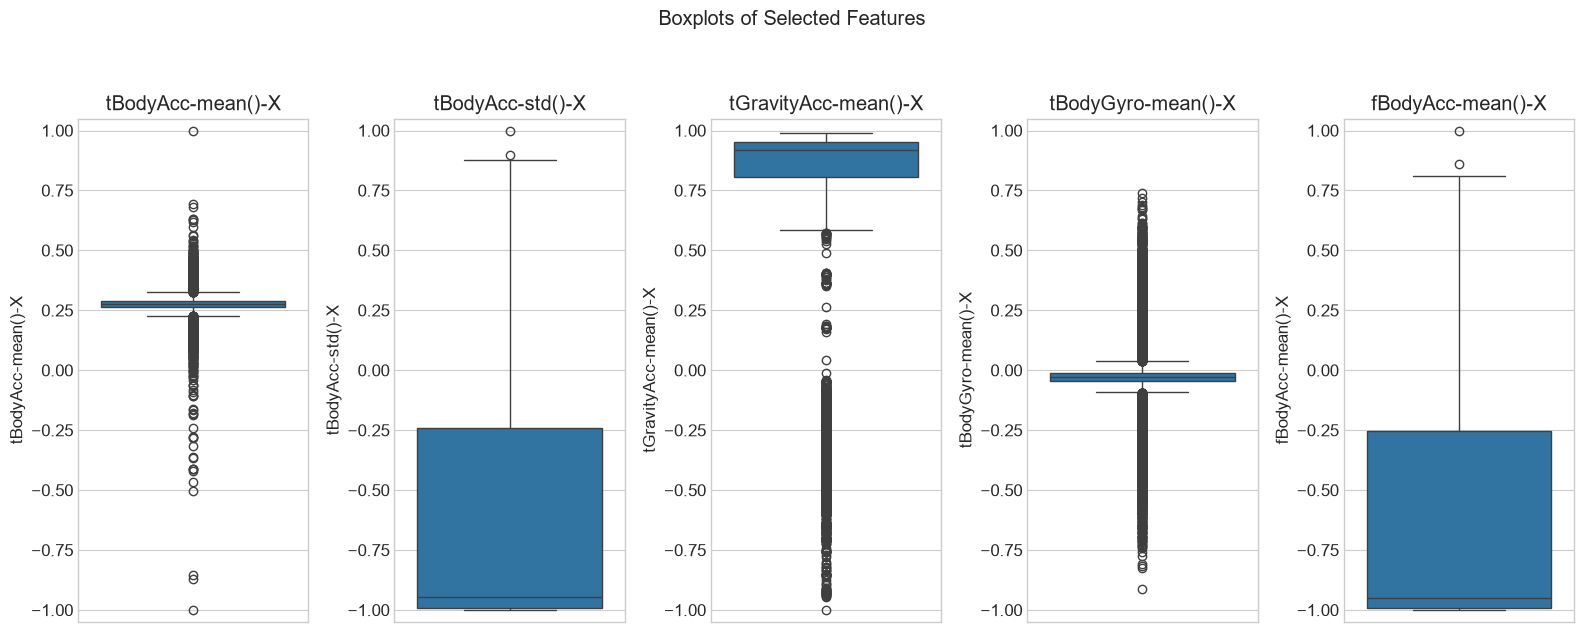

In [6]:
sample_features = [
    "tBodyAcc-mean()-X",
    "tBodyAcc-std()-X",
    "tGravityAcc-mean()-X",
    "tBodyGyro-mean()-X",
    "fBodyAcc-mean()-X"
]

fig, axes = plt.subplots(1, len(sample_features), figsize=(16, 6))
for i, col in enumerate(sample_features):
    sns.boxplot(y=train_df[col], ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_ylim(-1.05, 1.05)
plt.suptitle("Boxplots of Selected Features", y=1.05)
plt.tight_layout()
plt.show()

However, some do not and while all being in $[-1,1]$ does lessen the effect of ill-conditioned surfaces for gradient descent, the different distributions (mean and variances) could still affect it. **So I decide to standardize anyway just in case**.

Next, let's consider class distributions.

,Train Count,Train %,Test Count,Test %
Activity,,,,
LAYING,1407,19.14,537,18.22
SITTING,1286,17.49,491,16.66
STANDING,1374,18.69,532,18.05
WALKING,1226,16.68,496,16.83
WALKING_DOWNSTAIRS,986,13.41,420,14.25
WALKING_UPSTAIRS,1073,14.59,471,15.98


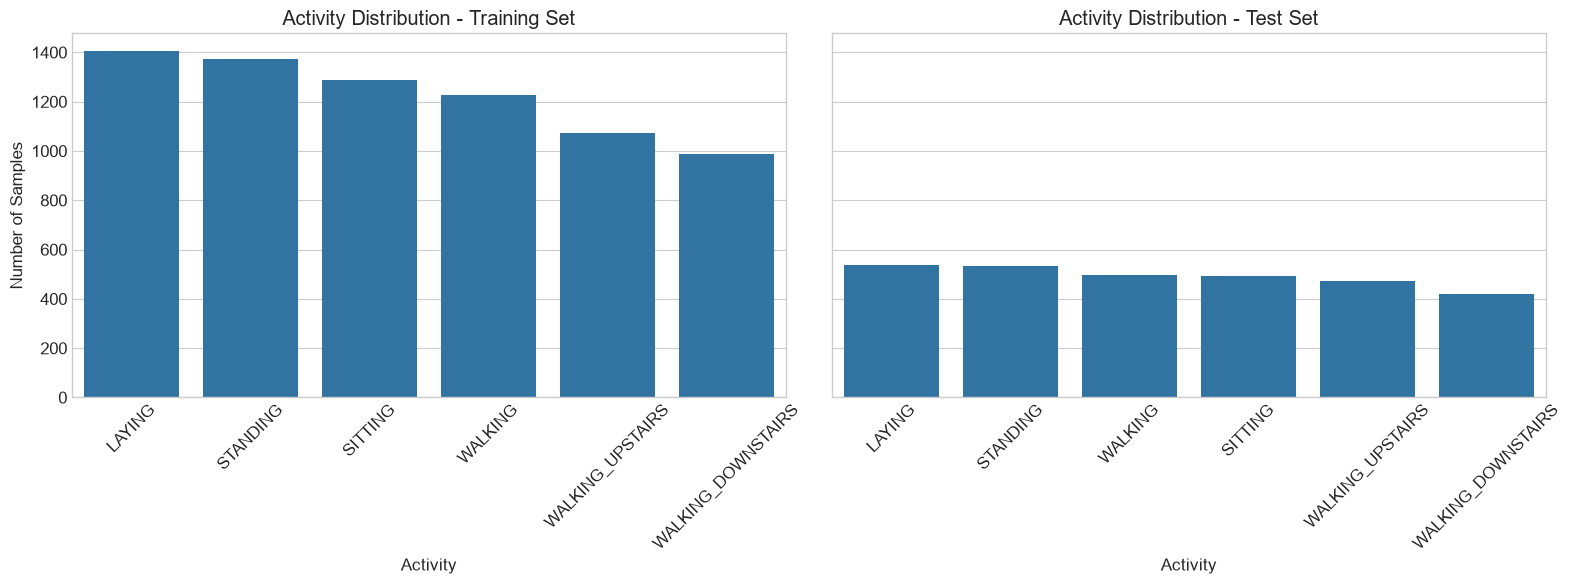

In [7]:
train_target_counts = train_df[target_col].value_counts()
test_target_counts = test_df[target_col].value_counts()

class_dist_df = pd.DataFrame({
    "Train Count": train_target_counts,
    "Train %": (train_target_counts / len(train_df) * 100).round(2),
    "Test Count": test_target_counts,
    "Test %": (test_target_counts / len(test_df) * 100).round(2)
})
display(class_dist_df)


fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

sns.barplot(
    x=train_target_counts.index,
    y=train_target_counts.values,
    ax=axes[0],
    legend=False
)
axes[0].set_title("Activity Distribution - Training Set")
axes[0].set_ylabel("Number of Samples")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(
    x=test_target_counts.index,
    y=test_target_counts.values,
    ax=axes[1],
    legend=False
)
axes[1].set_title("Activity Distribution - Test Set")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Classes are well-balanced with similar proportion between train and test sets and only a small $\approx 5%$ gap within set. So probably no extra augmentation or balancing is needed.

However, **we will still use imbalance-corrected metrics such as F1 to be certain.**

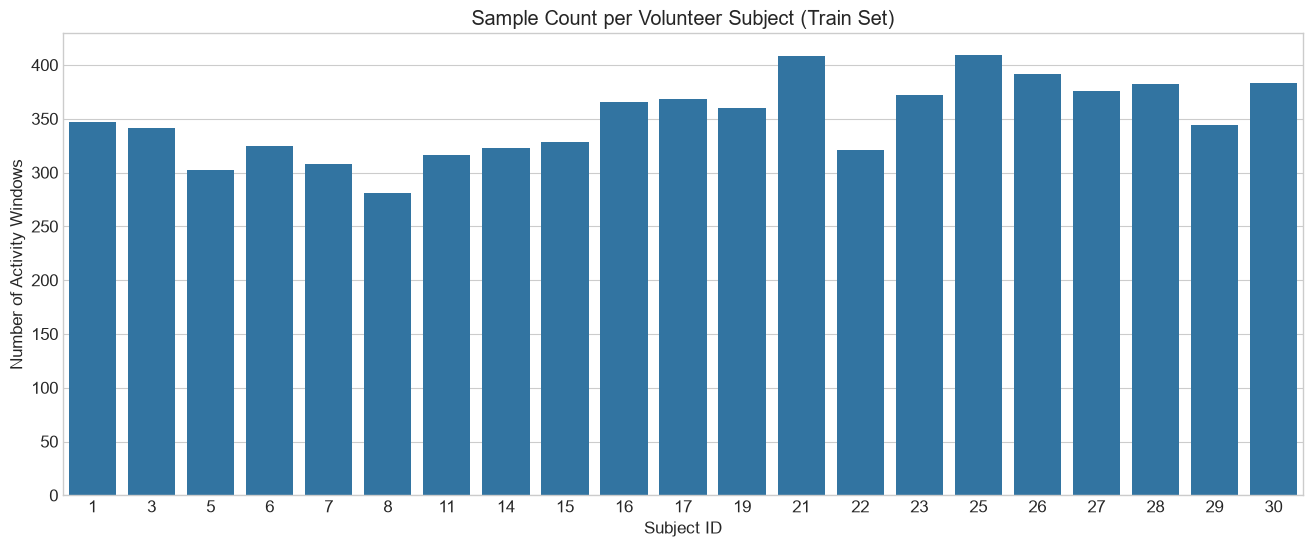

In [8]:
plt.figure(figsize=(16, 6))
train_subj_counts = train_df[subject_col].value_counts().sort_index()
sns.barplot(
    x=train_subj_counts.index,
    y=train_subj_counts.values,
)
plt.title("Sample Count per Volunteer Subject (Train Set)")
plt.xlabel("Subject ID")
plt.ylabel("Number of Activity Windows")
plt.show()

Number of activity per subject seems reasonably balanced.

### Correlations

My hypothesis is that each subjects will produces different measures, so the correlation within subject will be higher than that between subjects.

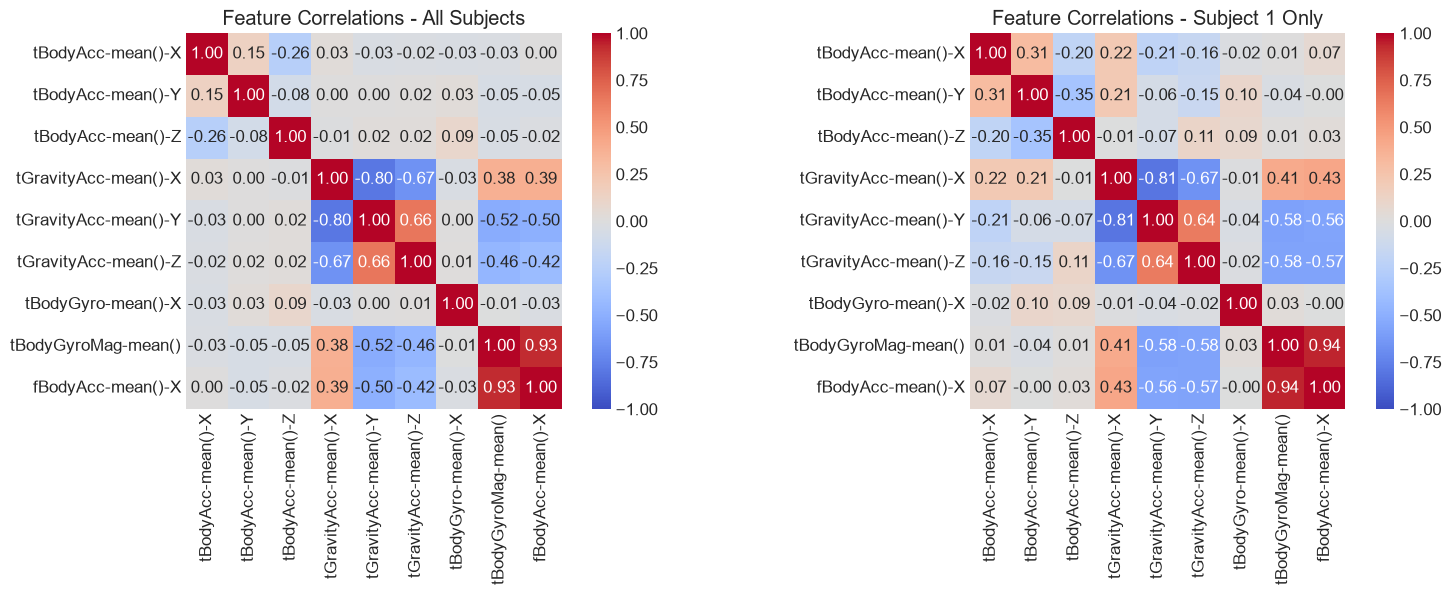

In [9]:
target_subject = 1  # Pick subject 1 as a representative volunteer
subj_df = train_df[train_df["subject"] == target_subject]
sample_features = [
    "tBodyAcc-mean()-X",
    "tBodyAcc-mean()-Y",
    "tBodyAcc-mean()-Z",
    "tGravityAcc-mean()-X",
    "tGravityAcc-mean()-Y",
    "tGravityAcc-mean()-Z",
    "tBodyGyro-mean()-X",
    "tBodyGyroMag-mean()",
    "fBodyAcc-mean()-X",
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
corr_all = train_df[sample_features].corr()
corr_subj = subj_df[sample_features].corr()
sns.heatmap(
    corr_all,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    cbar=True,
    square=True,
    ax=axes[0],
    vmin=-1,
    vmax=1,
)
axes[0].set_title("Feature Correlations - All Subjects")

sns.heatmap(
    corr_subj,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    cbar=True,
    square=True,
    ax=axes[1],
    vmin=-1,
    vmax=1,
)
axes[1].set_title(f"Feature Correlations - Subject {target_subject} Only")
plt.tight_layout()
plt.show()

Which is reasonably correct for some features. This means that when we split the data, **the whole subject must be included in only one split** to avoid data leakage.

Another thing worth noting is that autocorrelation within activity of a single subject is high.

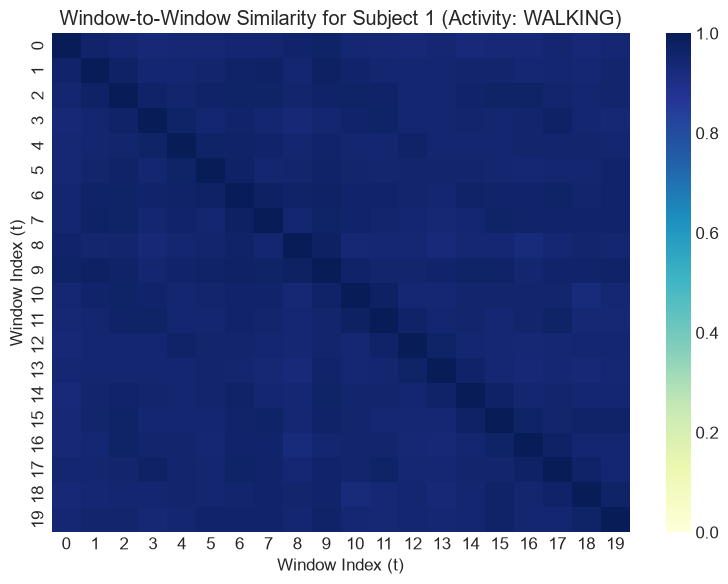

In [10]:
walking_subj = subj_df[subj_df["Activity"] == "WALKING"][feature_cols].values

from sklearn.metrics.pairwise import cosine_similarity
sim_matrix = cosine_similarity(walking_subj[:20])
plt.figure(figsize=(8, 6))
sns.heatmap(sim_matrix, cmap="YlGnBu", vmin=0, vmax=1.0)
plt.title(f"Window-to-Window Similarity for Subject {target_subject} (Activity: WALKING)")
plt.xlabel("Window Index (t)")
plt.ylabel("Window Index (t)")
plt.tight_layout()
plt.show()

However, since we are not doing any forcasting, **we must shuffle the data**.

### Conclusion

From the analysis, 
- we will need to standardize the data as eventhough features are in the range $[-1,1]$, the distributions are very different.
- we will also use imbalance-corrected metrics such as F1 or balanced-accuracy in case the slight imbalance causes a hidden problem.
- we must split such that a whole subject (and thus whole activities) is only in one split to avoid data leakage. After that, we must shuffle the data so that the model doesn't try to learn the ordering and that the gradient descent oscillate less.
- we will not remove any feature columns as the model can ignore columns itself.
- the `subject` column will not be fed into the model as the model will learn subject's identity instead of the actual motions performed. And as test subjects are completely unseen and each sample is independent, memorizing the identity will greatly impair generalization.

## Validation Strategy

As mentioned in the conclusion, a whole subject (thus whole activities) must remain in only one split to avoid data leakage due to within subject correlations and within activity autocorrelations.

After the split, data must be shuffled to stablize gradients.
Data should be standardized as well (based on training set statistics).

In [11]:
from sklearn.preprocessing import StandardScaler

# Map activity labels to integer targets 0..5
label_names = sorted(train_df[target_col].unique())
label_to_idx = {name: i for i, name in enumerate(label_names)}
idx_to_label = {i: name for name, i in label_to_idx.items()}

X_train_raw = train_df[feature_cols].values
y_train_raw = train_df[target_col].map(label_to_idx).values

X_test_raw = test_df[feature_cols].values
y_test = test_df[target_col].map(label_to_idx).values

train_df["subject"] = train_df["subject"].astype(int)
test_df["subject"] = test_df["subject"].astype(int)

RANDOM_STATE = 1
np.random.seed(RANDOM_STATE)

Random split (80% training, 20% validation):

In [12]:
X_tr_rand_raw, X_val_rand_raw, y_tr_rand, y_val_rand = train_test_split(
    X_train_raw,
    y_train_raw,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train_raw
)

scaler_rand = StandardScaler()
X_tr_rand = scaler_rand.fit_transform(X_tr_rand_raw)
X_val_rand = scaler_rand.transform(X_val_rand_raw)
X_test_from_rand = scaler_rand.transform(X_test_raw)

print(f"[Random Split]  Train: {X_tr_rand.shape[0]} samples | Val: {X_val_rand.shape[0]} samples")

[Random Split]  Train: 5881 samples | Val: 1471 samples


Subject-based split (5 training, 16 validation):

In [13]:
val_subjects = [26, 27, 28, 29, 30]
train_subjects = [int(s) for s in sorted(train_df["subject"].unique()) if s not in val_subjects]

val_mask = train_df["subject"].isin(val_subjects)
train_mask = ~val_mask

X_tr_subj_raw = train_df.loc[train_mask, feature_cols].values
y_tr_subj = train_df.loc[train_mask, target_col].map(label_to_idx).values

X_val_subj_raw = train_df.loc[val_mask, feature_cols].values
y_val_subj = train_df.loc[val_mask, target_col].map(label_to_idx).values

shuffle_indices = np.random.permutation(len(X_tr_subj_raw))
X_tr_subj_raw = X_tr_subj_raw[shuffle_indices]
y_tr_subj = y_tr_subj[shuffle_indices]

scaler_subj = StandardScaler()
X_tr_subj = scaler_subj.fit_transform(X_tr_subj_raw)
X_val_subj = scaler_subj.transform(X_val_subj_raw)
X_test_from_subj = scaler_subj.transform(X_test_raw)

print(f"[Subject Split] Train: {X_tr_subj.shape[0]} samples ({len(train_subjects)} subjects) | "
      f"Val: {X_val_subj.shape[0]} samples ({len(val_subjects)} subjects)")

print("\nValidation class counts:")
print(pd.Series(y_val_subj).map(idx_to_label).value_counts())

[Subject Split] Train: 5475 samples (16 subjects) | Val: 1877 samples (5 subjects)

Validation class counts:
LAYING                369
STANDING              357
SITTING               342
WALKING               288
WALKING_UPSTAIRS      271
WALKING_DOWNSTAIRS    250
Name: count, dtype: int64


## Baseline

To answer the questions mentioned, we will demonstrate with the baseline model trained on the random split and subject-based split data. For each, we compute the accuracy, balanced accuracy, F1-score.

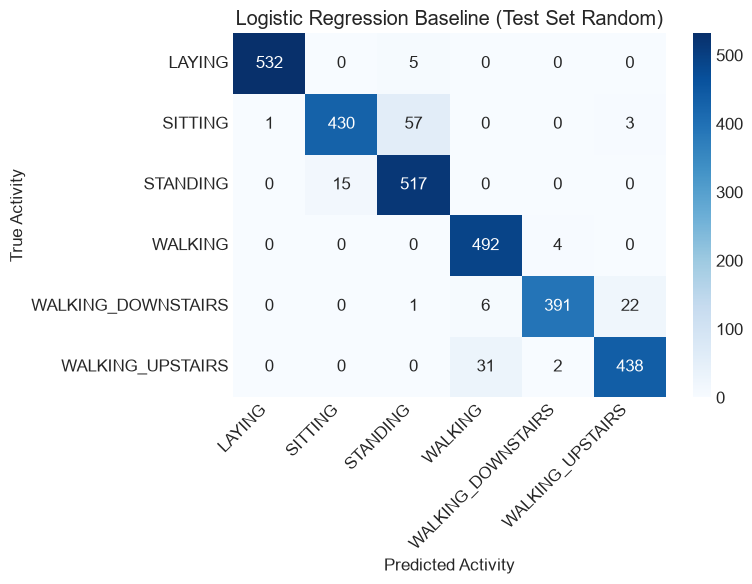

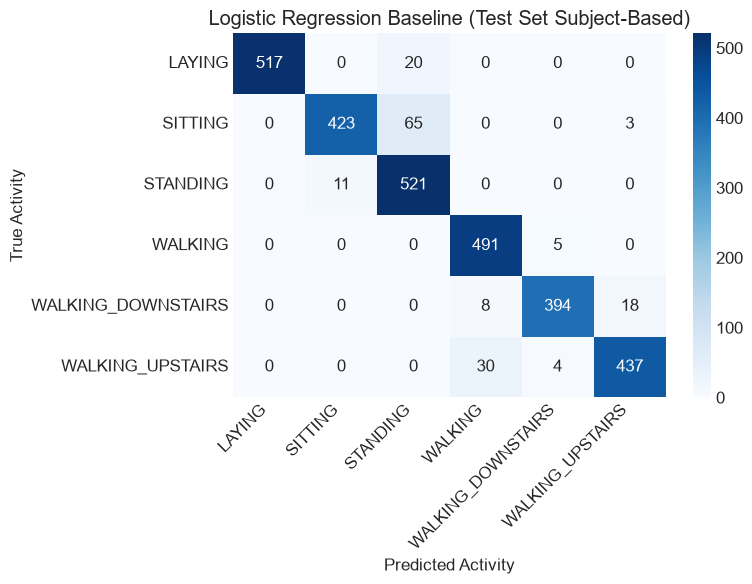

,Split Strategy,Val Accuracy (%),Val Macro F1 (%),Val Balanced Accuracy (%),Test Accuracy (%),Test Macro F1 (%),Test Balanced Accuracy (%),Generalization Gap (|Val - Test| Acc) (%)
0,Random Row Split,98.440172,98.442674,98.440172,94.851357,94.968565,94.851357,3.588814
1,Subject-Based Split,97.162567,97.177980,97.162567,94.323571,94.459646,94.323571,2.838997


In [14]:
from sklearn.metrics import balanced_accuracy_score


def evaluate_model(model, title, X_train, y_train, X_val, y_val, X_test, y_test):
    model.fit(X_train, y_train)

    pred_val = model.predict(X_val)
    pred_test = model.predict(X_test)

    acc_val = accuracy_score(y_val, pred_val)
    f1_val = f1_score(y_val, pred_val, average="macro")
    bal_acc_val = balanced_accuracy_score(y_val, pred_val)

    acc_test = accuracy_score(y_test, pred_test)
    f1_test = f1_score(y_test, pred_test, average="macro")
    bal_acc_test = balanced_accuracy_score(y_test, pred_test)

    cm = confusion_matrix(y_test, pred_test)

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_names,
        yticklabels=label_names
    )
    plt.title(f"Logistic Regression Baseline (Test Set {title})")
    plt.xlabel("Predicted Activity")
    plt.ylabel("True Activity")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    return {
        "pred_val": pred_val,
        "pred_test": pred_test,
        "acc_val": acc_val,
        "f1_val": f1_val,
        "bal_acc_val": bal_acc_val,
        "acc_test": acc_test,
        "f1_test": f1_test,
        "bal_acc_test": bal_acc_test
    }


# Train on Random Split
log_reg_rand = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, solver="lbfgs")
results_rand = evaluate_model(
    log_reg_rand, "Random", X_tr_rand, y_tr_rand, X_val_rand, y_val_rand, X_test_from_rand, y_test
)

# Train on Subject-based Split
log_reg_subj = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, solver="lbfgs")
results_subj = evaluate_model(
    log_reg_subj, "Subject-Based", X_tr_subj, y_tr_subj, X_val_subj, y_val_subj, X_test_from_subj, y_test
)

comparison_df = pd.DataFrame({
    "Split Strategy": ["Random Row Split", "Subject-Based Split"],
    "Val Accuracy (%)": [results_rand["bal_acc_val"] * 100, results_subj["bal_acc_val"] * 100],
    "Val Macro F1 (%)": [results_rand["f1_val"] * 100, results_subj["f1_val"] * 100],
    "Val Balanced Accuracy (%)": [results_rand["bal_acc_val"] * 100, results_subj["bal_acc_val"] * 100],
    "Test Accuracy (%)": [results_rand["bal_acc_test"] * 100, results_subj["bal_acc_test"] * 100],
    "Test Macro F1 (%)": [results_rand["f1_test"] * 100, results_subj["f1_test"] * 100],
    "Test Balanced Accuracy (%)": [results_rand["bal_acc_test"] * 100, results_subj["bal_acc_test"] * 100],
    "Generalization Gap (|Val - Test| Acc) (%)": [
        abs(results_rand["bal_acc_val"] - results_rand["bal_acc_test"]) * 100,
        abs(results_subj["bal_acc_val"] - results_subj["bal_acc_test"]) * 100
    ]
})

display(comparison_df)

### Conclusion

The random split gives an artificially high accuracy as subject traits and samples of the same activities leaked into the validation set, making it further from the test accuracy compared to the subject-based split. Thus, the subject-based split gernalizes better.

The baseline achieves a strong test accuracy of around 94.3%.

The confusion matrix shows that errors occur mostly between sitting and standing (static postures), and walking poses.

In [15]:
import os
import json
import torch

OUTPUT_DIR = os.path.join("data", "processed")
os.makedirs(OUTPUT_DIR, exist_ok=True)

npz_path = os.path.join(OUTPUT_DIR, "har_dataset.npz")
np.savez_compressed(
    npz_path,
    X_train=X_tr_subj,
    y_train=y_tr_subj,
    X_val=X_val_subj,
    y_val=y_val_subj,
    X_test=X_test_from_subj,
    y_test=y_test,
    label_names=np.array(label_names)
)
print(f"NumPy dataset saved to: {npz_path}")

pt_path = os.path.join(OUTPUT_DIR, "har_tensors.pt")
torch_data = {
    "X_train": torch.tensor(X_tr_subj, dtype=torch.float32),
    "y_train": torch.tensor(y_tr_subj, dtype=torch.long),
    "X_val": torch.tensor(X_val_subj, dtype=torch.float32),
    "y_val": torch.tensor(y_val_subj, dtype=torch.long),
    "X_test": torch.tensor(X_test_from_subj, dtype=torch.float32),
    "y_test": torch.tensor(y_test, dtype=torch.long),
    "label_names": label_names,
    "label_to_idx": label_to_idx,
    "idx_to_label": idx_to_label
}
torch.save(torch_data, pt_path)
print(f"PyTorch tensors saved to: {pt_path}")

meta_path = os.path.join(OUTPUT_DIR, "metadata.json")
metadata = {
    "num_features": len(feature_cols),
    "feature_names": feature_cols,
    "label_to_idx": label_to_idx,
    "val_subjects": val_subjects,
    "train_subjects": train_subjects,
    "shapes": {
        "X_train": list(X_tr_subj.shape),
        "y_train": list(y_tr_subj.shape),
        "X_val": list(X_val_subj.shape),
        "y_val": list(y_val_subj.shape),
        "X_test": list(X_test_from_subj.shape),
        "y_test": list(y_test.shape)
    }
}
with open(meta_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)
print(f"Metadata saved to: {meta_path}")

NumPy dataset saved to: data\processed\har_dataset.npz
PyTorch tensors saved to: data\processed\har_tensors.pt
Metadata saved to: data\processed\metadata.json
